# 📧 Spam vs Ham Classifier (SMS Spam Collection)

**Goal:** Build a model that reads a text message and tells us if it is **spam** or **ham** (not spam).

**Steps we will follow**
1. Load the messages and labels
2. Look at the data (EDA)
3. Preprocess the text (lowercase, tokenization, remove stopwords)
4. Convert text to numbers (Bag of Words / TF-IDF)
5. Split into train and test sets
6. Train models (Naive Bayes, Logistic Regression)
7. Measure performance (accuracy, precision, recall, F1)
8. Test with our own messages

## Step 1: Import Libraries
We import everything we need at the start.
- `pandas`, `numpy` → work with data
- `matplotlib`, `seaborn` → draw charts
- `re` → clean text
- `sklearn` → vectorizer, models, metrics

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

print("Libraries imported successfully")

Libraries imported successfully


## Step 2: Load the Dataset
The file is `spam.csv` (SMS Spam Collection from UCI).
It has some special characters, so we use `encoding='latin-1'`, otherwise pandas gives an error.

In [2]:
df = pd.read_csv("spam.csv", encoding="latin-1")
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [3]:
print("Rows and columns:", df.shape)

Rows and columns: (5572, 5)


### Clean the columns
We can see 5 columns, but only the first two are useful:
- `v1` → label (ham / spam)
- `v2` → the message text

The other 3 columns are almost empty, so we drop them and give the columns better names.

In [4]:
df = df[["v1", "v2"]]
df.columns = ["label", "message"]
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## Step 3: Understand the Data (EDA)
Before building any model, we should know what our data looks like.

In [5]:
# Basic info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [6]:
# Missing values
print("Missing values:")
print(df.isnull().sum())

Missing values:
label      0
message    0
dtype: int64


In [7]:
# Duplicate messages
print("Duplicate messages:", df.duplicated().sum())

Duplicate messages: 403


There are many duplicate messages. If the same message is in both train and test data, the model sees the answer
before the exam, and the score looks better than it really is. So we remove the duplicates.

In [8]:
df = df.drop_duplicates()
df = df.reset_index(drop=True)
print("Rows after removing duplicates:", df.shape[0])

Rows after removing duplicates: 5169


### How many spam and ham messages?

In [9]:
print(df["label"].value_counts())
print()
print(df["label"].value_counts(normalize=True) * 100)

label
ham     4516
spam     653
Name: count, dtype: int64

label
ham     87.366996
spam    12.633004
Name: proportion, dtype: float64


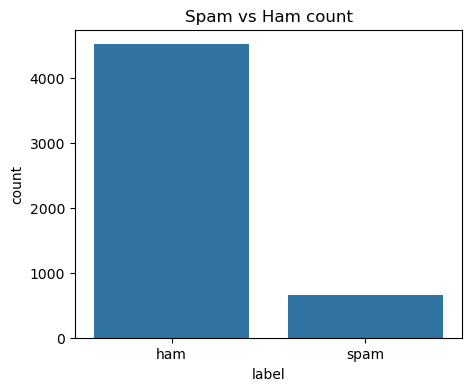

In [10]:
plt.figure(figsize=(5, 4))
sns.countplot(x="label", data=df)
plt.title("Spam vs Ham count")
plt.show()

**Observation:** The data is **imbalanced**. Ham is much more than spam.
So only *accuracy* is not enough to judge the model. That is why we also check precision, recall and F1 later.

### Message length: spam vs ham

In [11]:
df["length"] = df["message"].apply(len)
print(df.groupby("label")["length"].mean())

label
ham      70.459256
spam    137.891271
Name: length, dtype: float64


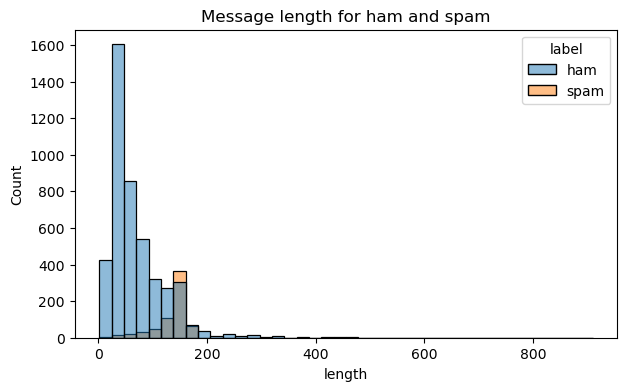

In [12]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="length", hue="label", bins=40)
plt.title("Message length for ham and spam")
plt.show()

**Observation:** Spam messages are usually longer than ham messages. Spammers write long offers and details.

### Look at some real messages

In [13]:
print("---- HAM examples ----")
for msg in df[df["label"] == "ham"]["message"].head(3):
    print("*", msg)

print()
print("---- SPAM examples ----")
for msg in df[df["label"] == "spam"]["message"].head(3):
    print("*", msg)

---- HAM examples ----
* Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
* Ok lar... Joking wif u oni...
* U dun say so early hor... U c already then say...

---- SPAM examples ----
* Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
* FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, å£1.50 to rcv
* WINNER!! As a valued network customer you have been selected to receivea å£900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.


## Step 4: Convert Labels to Numbers
Machine learning models understand numbers, not words.
- ham → **0**
- spam → **1**

In [14]:
df["label_num"] = df["label"].map({"ham": 0, "spam": 1})
df[["label", "label_num"]].head()

,label,label_num
0,ham,0
1,ham,0
2,spam,1
3,ham,0
4,ham,0


## Step 5: Text Preprocessing
Raw text is messy. We clean it in these steps:

| Step | What it does | Example |
|---|---|---|
| Lowercasing | `FREE` and `free` become the same word | `FREE Entry` → `free entry` |
| Remove punctuation/numbers | keep only letters | `win £100!!` → `win` |
| Tokenization | split sentence into words | `free entry` → `['free', 'entry']` |
| Stopword removal | remove common words that do not help (is, the, a, to...) | `['you', 'won', 'the', 'prize']` → `['won', 'prize']` |

**Stopwords:** we try to use NLTK's list. If NLTK is not installed or there is no internet, we use the same
list written manually, so the notebook works either way.

In [15]:
try:
    import nltk
    nltk.download("stopwords", quiet=True)
    from nltk.corpus import stopwords
    stop_words = set(stopwords.words("english"))
    print("Using NLTK stopwords")
except Exception:
    stop_words = set('''i me my myself we our ours ourselves you your yours yourself yourselves he him his himself
    she her hers herself it its itself they them their theirs themselves what which who whom this that these those
    am is are was were be been being have has had having do does did doing a an the and but if or because as until
    while of at by for with about against between into through during before after above below to from up down in
    out on off over under again further then once here there when where why how all any both each few more most
    other some such no nor not only own same so than too very s t can will just don should now d ll m o re ve y
    ain aren couldn didn doesn hadn hasn haven isn ma mightn mustn needn shan shouldn wasn weren won wouldn'''.split())
    print("NLTK not available, using manual stopwords list")

print("Number of stopwords:", len(stop_words))

Using NLTK stopwords
Number of stopwords: 198


Let's first try the steps on **one message** to see what happens.

In [16]:
sample = df["message"][2]
print("Original      :", sample)

# 1. lowercase
step1 = sample.lower()
print("Lowercase     :", step1)

# 2. remove everything except letters
step2 = re.sub("[^a-z]", " ", step1)
print("Only letters  :", step2)

# 3. tokenization (split into words)
step3 = step2.split()
print("Tokens        :", step3)

# 4. remove stopwords
step4 = [word for word in step3 if word not in stop_words]
print("No stopwords  :", step4)

Original      : Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
Lowercase     : free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005. text fa to 87121 to receive entry question(std txt rate)t&c's apply 08452810075over18's
Only letters  : free entry in   a wkly comp to win fa cup final tkts   st may       text fa to       to receive entry question std txt rate t c s apply            over   s
Tokens        : ['free', 'entry', 'in', 'a', 'wkly', 'comp', 'to', 'win', 'fa', 'cup', 'final', 'tkts', 'st', 'may', 'text', 'fa', 'to', 'to', 'receive', 'entry', 'question', 'std', 'txt', 'rate', 't', 'c', 's', 'apply', 'over', 's']
No stopwords  : ['free', 'entry', 'wkly', 'comp', 'win', 'fa', 'cup', 'final', 'tkts', 'st', 'may', 'text', 'fa', 'receive', 'entry', 'question', 'std', 'txt', 'rate', 'c', 'apply']


Now we put these steps into one function and apply it on the whole dataset.

In [17]:
def clean_text(text):
    text = text.lower()                          # lowercase
    text = re.sub("[^a-z]", " ", text)           # keep only letters
    words = text.split()                         # tokenization
    words = [w for w in words if w not in stop_words]   # remove stopwords
    return " ".join(words)                       # join words back into a sentence

df["clean_message"] = df["message"].apply(clean_text)
df[["message", "clean_message"]].head()

,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goes usf lives around though


### Most common words in spam and ham (after cleaning)

In [18]:
spam_words = " ".join(df[df["label"] == "spam"]["clean_message"]).split()
ham_words = " ".join(df[df["label"] == "ham"]["clean_message"]).split()

print("Top 10 SPAM words:")
print(pd.Series(spam_words).value_counts().head(10))
print()
print("Top 10 HAM words:")
print(pd.Series(ham_words).value_counts().head(10))

Top 10 SPAM words:
call      322
free      197
p         158
u         157
txt       141
ur        119
stop      114
mobile    111
text      109
reply      96
Name: count, dtype: int64

Top 10 HAM words:
u       922
get     301
gt      288
lt      287
ok      255
go      245
got     227
know    225
like    222
good    215
Name: count, dtype: int64


**Observation:** Spam has words like *call, free, txt, stop, mobile, claim*. Ham has normal talking words (*get, ok, go, know, good*). This is exactly what our model will learn.

## Step 6: Convert Text into Numbers (Bag of Words and TF-IDF)

### Bag of Words (BoW)
Count how many times each word appears in a message. Word order is ignored (like words thrown in a bag).

### TF-IDF
Counting has one problem: common words get high numbers even if they are not useful.
TF-IDF fixes this:
- **TF** (term frequency) = how often a word is in this message
- **IDF** (inverse document frequency) = how rare the word is in all messages

A word that is **rare overall but present in this message** gets a high score. So it is more informative.

Let's see a tiny example with 3 sentences:

In [19]:
small_text = ["win free prize now", "free entry win", "see you at lunch"]

cv = CountVectorizer()
bow = cv.fit_transform(small_text)

print("Words (columns):", cv.get_feature_names_out())
print()
print(pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out()))

Words (columns): ['at' 'entry' 'free' 'lunch' 'now' 'prize' 'see' 'win' 'you']

   at  entry  free  lunch  now  prize  see  win  you
0   0      0     1      0    1      1    0    1    0
1   0      1     1      0    0      0    0    1    0
2   1      0     0      1    0      0    1    0    1


In [20]:
tv = TfidfVectorizer()
tfidf_small = tv.fit_transform(small_text)

print(pd.DataFrame(tfidf_small.toarray().round(2), columns=tv.get_feature_names_out()))

    at  entry  free  lunch   now  prize  see   win  you
0  0.0   0.00  0.43    0.0  0.56   0.56  0.0  0.43  0.0
1  0.0   0.68  0.52    0.0  0.00   0.00  0.0  0.52  0.0
2  0.5   0.00  0.00    0.5  0.00   0.00  0.5  0.00  0.5


In the TF-IDF table, `win` and `free` appear in 2 of 3 sentences, so they get a lower score than `prize` or `lunch`,
which appear in only one sentence.

## Step 7: Train / Test Split
We keep 80% of data to **train** the model and 20% to **test** it on messages it has never seen.

- `random_state=42` → same split every time we run
- `stratify=y` → keeps the same spam/ham ratio in both train and test (important for imbalanced data)

In [21]:
X = df["clean_message"]     # input (text)
y = df["label_num"]         # output (0 or 1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training messages:", X_train.shape[0])
print("Testing messages :", X_test.shape[0])
print()
print("Spam % in train:", round(y_train.mean() * 100, 2))
print("Spam % in test :", round(y_test.mean() * 100, 2))

Training messages: 4135
Testing messages : 1034

Spam % in train: 12.62
Spam % in test : 12.67


### Apply TF-IDF on the real data
Very important rule: `fit` the vectorizer only on **training data**, then only `transform` the test data.
If we fit on test data also, information from the test set leaks into training (called *data leakage*).

In [22]:
tfidf = TfidfVectorizer()

X_train_tfidf = tfidf.fit_transform(X_train)   # learn vocabulary + transform
X_test_tfidf = tfidf.transform(X_test)         # only transform

print("Train shape:", X_train_tfidf.shape)
print("Test shape :", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.get_feature_names_out()))

Train shape: (4135, 6608)
Test shape : (1034, 6608)
Vocabulary size: 6608


Each message is now a row of numbers. The columns are the unique words in our data.

## Step 8: Model 1: Naive Bayes
**Simple idea:** It uses probability. For every word it learns *"how often does this word come in spam vs in ham?"*.
When a new message comes, it combines the probabilities of all its words and picks the class with the higher chance.
It is very fast and works very well for text.

In [23]:
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

nb_pred = nb_model.predict(X_test_tfidf)
print("Naive Bayes model trained")

Naive Bayes model trained


## Step 9: Model 2: Logistic Regression
**Simple idea:** It gives a weight to every word. Spam-like words (free, prize) get a positive weight, normal words
get a negative weight. It adds all the weights of a message and converts the total into a probability between 0 and 1.
If probability is more than 0.5, the message is spam.

In [24]:
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

lr_pred = lr_model.predict(X_test_tfidf)
print("Logistic Regression model trained")

Logistic Regression model trained


## Step 10: Evaluate the Models

| Metric | Question it answers |
|---|---|
| **Accuracy** | Out of all messages, how many did we predict correctly? |
| **Precision** | Out of messages we called spam, how many were really spam? (high = few ham messages blocked) |
| **Recall** | Out of all real spam, how many did we catch? (high = few spam messages missed) |
| **F1 score** | Balance of precision and recall in one number |

For spam detection, **precision** is important because we don't want to put a real message in the spam folder.

In [25]:
print("===== Naive Bayes =====")
print("Accuracy :", round(accuracy_score(y_test, nb_pred), 4))
print("Precision:", round(precision_score(y_test, nb_pred), 4))
print("Recall   :", round(recall_score(y_test, nb_pred), 4))
print("F1 score :", round(f1_score(y_test, nb_pred), 4))

print()
print("===== Logistic Regression =====")
print("Accuracy :", round(accuracy_score(y_test, lr_pred), 4))
print("Precision:", round(precision_score(y_test, lr_pred), 4))
print("Recall   :", round(recall_score(y_test, lr_pred), 4))
print("F1 score :", round(f1_score(y_test, lr_pred), 4))

===== Naive Bayes =====
Accuracy : 0.9662
Precision: 0.9898
Recall   : 0.7405
F1 score : 0.8472

===== Logistic Regression =====
Accuracy : 0.9594
Precision: 0.989
Recall   : 0.687
F1 score : 0.8108


### Confusion Matrix
Shows exactly where the model is right and wrong.

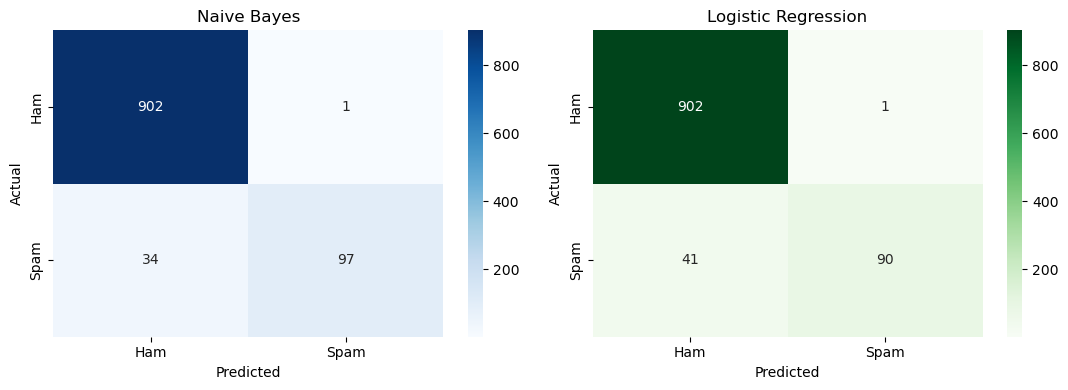

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

cm_nb = confusion_matrix(y_test, nb_pred)
sns.heatmap(cm_nb, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"])
axes[0].set_title("Naive Bayes")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

cm_lr = confusion_matrix(y_test, lr_pred)
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Greens", ax=axes[1],
            xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"])
axes[1].set_title("Logistic Regression")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

How to read it:
- **Top-left** → ham predicted as ham ✅
- **Bottom-right** → spam predicted as spam ✅
- **Top-right** → ham wrongly predicted as spam ❌ (a good message gets blocked)
- **Bottom-left** → spam wrongly predicted as ham ❌ (spam reaches the inbox)

### Full classification report

In [28]:
print("Naive Bayes")
print(classification_report(y_test, nb_pred, target_names=["Ham", "Spam"]))

print("Logistic Regression")
print(classification_report(y_test, lr_pred, target_names=["Ham", "Spam"]))

Naive Bayes
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       903
        Spam       0.99      0.74      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.91      1034
weighted avg       0.97      0.97      0.96      1034

Logistic Regression
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       903
        Spam       0.99      0.69      0.81       131

    accuracy                           0.96      1034
   macro avg       0.97      0.84      0.89      1034
weighted avg       0.96      0.96      0.96      1034



### Compare both models

In [29]:
results = pd.DataFrame({
    "Model": ["Naive Bayes", "Logistic Regression"],
    "Accuracy": [accuracy_score(y_test, nb_pred), accuracy_score(y_test, lr_pred)],
    "Precision": [precision_score(y_test, nb_pred), precision_score(y_test, lr_pred)],
    "Recall": [recall_score(y_test, nb_pred), recall_score(y_test, lr_pred)],
    "F1 Score": [f1_score(y_test, nb_pred), f1_score(y_test, lr_pred)],
})
results = results.round(4)
results

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,0.9662,0.9898,0.7405,0.8472
1,Logistic Regression,0.9594,0.9890,0.6870,0.8108


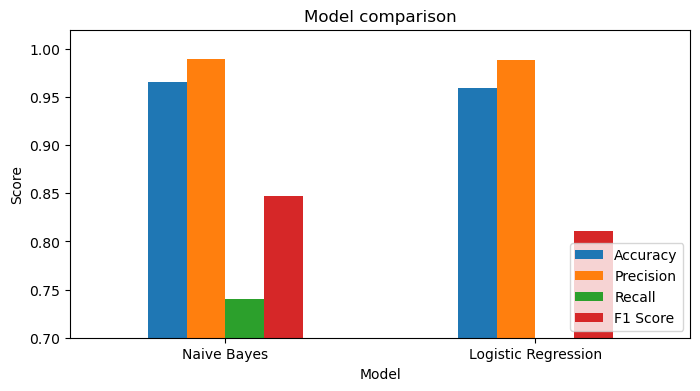

In [30]:
results.set_index("Model").plot(kind="bar", figsize=(8, 4))
plt.title("Model comparison")
plt.ylabel("Score")
plt.ylim(0.7, 1.02)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

## Step 11: Bag of Words vs TF-IDF
The task says BoW *or* TF-IDF. We used TF-IDF above. Let's also try BoW with the same models and compare.

In [31]:
bow_vec = CountVectorizer()
X_train_bow = bow_vec.fit_transform(X_train)
X_test_bow = bow_vec.transform(X_test)

nb_bow = MultinomialNB().fit(X_train_bow, y_train)
lr_bow = LogisticRegression(max_iter=1000).fit(X_train_bow, y_train)

nb_bow_pred = nb_bow.predict(X_test_bow)
lr_bow_pred = lr_bow.predict(X_test_bow)

compare = pd.DataFrame({
    "Model + Features": ["Naive Bayes + BoW", "Naive Bayes + TF-IDF",
                         "Logistic Reg + BoW", "Logistic Reg + TF-IDF"],
    "Accuracy": [accuracy_score(y_test, nb_bow_pred), accuracy_score(y_test, nb_pred),
                 accuracy_score(y_test, lr_bow_pred), accuracy_score(y_test, lr_pred)],
    "Precision": [precision_score(y_test, nb_bow_pred), precision_score(y_test, nb_pred),
                  precision_score(y_test, lr_bow_pred), precision_score(y_test, lr_pred)],
    "Recall": [recall_score(y_test, nb_bow_pred), recall_score(y_test, nb_pred),
               recall_score(y_test, lr_bow_pred), recall_score(y_test, lr_pred)],
    "F1 Score": [f1_score(y_test, nb_bow_pred), f1_score(y_test, nb_pred),
                 f1_score(y_test, lr_bow_pred), f1_score(y_test, lr_pred)],
})
compare.round(4)

,Model + Features,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes + BoW,0.9826,0.9449,0.9160,0.9302
1,Naive Bayes + TF-IDF,0.9662,0.9898,0.7405,0.8472
2,Logistic Reg + BoW,0.9768,0.9908,0.8244,0.9000
3,Logistic Reg + TF-IDF,0.9594,0.9890,0.6870,0.8108


**Observation:** In our run, **Bag of Words gave a better F1 score than TF-IDF** for both models.
TF-IDF made the models very careful (precision is high, around 0.99) but they **missed more spam** (recall is lower).
So TF-IDF is not always the winner. We should test both and choose using the data.

## Step 12: Which words make a message spam?
Logistic Regression gives a weight to each word, so we can see which words push the prediction to spam
(big positive weight) and which push it to ham (big negative weight).

In [32]:
words = tfidf.get_feature_names_out()
weights = lr_model.coef_[0]

word_weights = pd.DataFrame({"word": words, "weight": weights})
word_weights = word_weights.sort_values("weight", ascending=False)

print("Top 10 SPAM words:")
print(word_weights.head(10).to_string(index=False))
print()
print("Top 10 HAM words:")
print(word_weights.tail(10).to_string(index=False))

Top 10 SPAM words:
  word   weight
   txt 4.430946
mobile 3.651589
  call 3.420439
 reply 3.343328
 claim 3.331902
  stop 3.310824
   www 3.197066
  text 3.058373
    uk 2.983570
  free 2.905529

Top 10 HAM words:
 word    weight
  sir -1.070429
going -1.079211
later -1.107949
   da -1.121032
  got -1.188556
 come -1.209943
 home -1.289973
   gt -1.447840
   lt -1.470145
   ok -1.650669


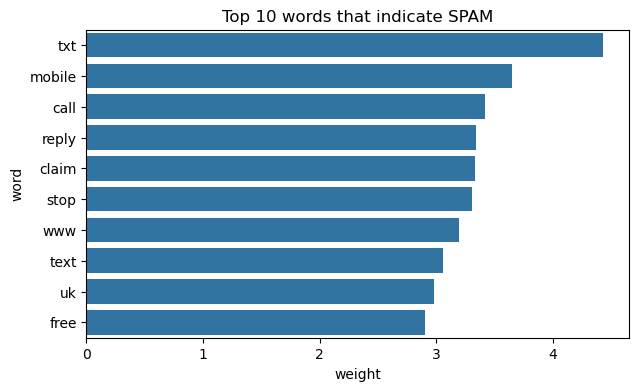

In [33]:
top_spam = word_weights.head(10)
plt.figure(figsize=(7, 4))
sns.barplot(x="weight", y="word", data=top_spam)
plt.title("Top 10 words that indicate SPAM")
plt.show()

## Step 13: Test with Our Own Messages
Now the fun part. We take a new message, clean it, convert it using the **same** TF-IDF, and predict.

In [34]:
def predict_message(text):
    cleaned = clean_text(text)
    vector = tfidf.transform([cleaned])

    nb_result = nb_model.predict(vector)[0]
    lr_result = lr_model.predict(vector)[0]
    lr_prob = lr_model.predict_proba(vector)[0][1]

    labels = {0: "HAM", 1: "SPAM"}
    print("Message :", text)
    print("Naive Bayes         :", labels[nb_result])
    print("Logistic Regression :", labels[lr_result], "(spam probability:", round(lr_prob * 100, 1), "%)")
    print("-" * 60)

predict_message("Congratulations! You have won a free prize. Call 0800 now to claim your reward")
predict_message("Hey, are we meeting for lunch tomorrow?")
predict_message("URGENT! Your mobile number has been selected for a 1000 cash award. Txt WIN to 80086")
predict_message("Please send me the notes from today's class")

Message : Congratulations! You have won a free prize. Call 0800 now to claim your reward
Naive Bayes         : SPAM
Logistic Regression : SPAM (spam probability: 89.4 %)
------------------------------------------------------------
Message : Hey, are we meeting for lunch tomorrow?
Naive Bayes         : HAM
Logistic Regression : HAM (spam probability: 2.1 %)
------------------------------------------------------------
Message : URGENT! Your mobile number has been selected for a 1000 cash award. Txt WIN to 80086
Naive Bayes         : SPAM
Logistic Regression : SPAM (spam probability: 96.4 %)
------------------------------------------------------------
Message : Please send me the notes from today's class
Naive Bayes         : HAM
Logistic Regression : HAM (spam probability: 9.9 %)
------------------------------------------------------------


## Step 14: Conclusion

**What we did**
1. Loaded the SMS Spam Collection (5,572 messages) and removed duplicates
2. Cleaned the text: lowercase → remove punctuation → tokenization → remove stopwords
3. Converted text to numbers with Bag of Words and TF-IDF
4. Split the data 80/20 (stratified)
5. Trained Naive Bayes and Logistic Regression
6. Evaluated with accuracy, precision, recall, F1 and confusion matrix

**Key points**
- Data is imbalanced, so accuracy alone is not enough. We looked at precision, recall and F1 also.
- Naive Bayes is simple and fast. Logistic Regression is a little more flexible and also tells us which words matter.
- Fit the vectorizer on training data only, to avoid data leakage.
- In our run, Bag of Words beat TF-IDF on F1 because recall was better. The best choice depends on the data, so always compare.
- Precision is very high for all models (few real messages blocked), but recall is the weak point (some spam is missed).

**How to improve it further**
- Try stemming or lemmatization
- Handle the low recall of TF-IDF models (for example `class_weight='balanced'` in Logistic Regression)
- Use n-grams (`ngram_range=(1, 2)`) in TF-IDF
- Keep numbers or add features like message length
- Try other models (SVM, Random Forest) and tune hyperparameters with GridSearchCV
- Save the model with `joblib` and build a small web app